<div style="border-bottom:3px solid #2c3e50;padding-bottom:10px;margin-bottom:10px">

# Valorisation de stockage de gaz par switching optimal
## Notebook 02 — Exemple 3 — modèle de prix à deux facteurs avec sauts


</div>

Ce notebook étend le moteur de switching optimal à un modèle de prix **à deux facteurs**
$G = G^{(1)} e^{G^{(2)}}$ : un facteur de fond $G^{(1)}$ (retour à la moyenne) et un facteur
de spike $G^{(2)}$ (sauts de Poisson). Il démontre l'extensibilité de l'architecture au cas
multi-facteurs et produit la surface de fonction valeur (Figure 3). Estimateur : BLSM-grille.

**Conventions** : $G$ prix, $C$ inventaire, régimes $\{-1,0,1\}$ ; $M$ pas, $N$ chemins, $deg$ degré base ; $V_0$ valeur, IC95 demi-intervalle de confiance.


## Code — moteur deux-facteurs découplé et surface de valeur

Version **alignée sur le moteur principal** : régression découplée (continuation pure régressée sur la base au prix présent), décision *forward* sans look-ahead. La surface tracée est la continuation au régime *store* à $t=1$ ; sa forme en bol asymétrique (croissante en $g_1$, $g_2$ et en inventaire) reproduit Carmona–Ludkovski.

G1 mean=5.94 | G2 mean=0.000 std=0.055 | G total mean=5.95
V0 (forward Pathwise, c=C0=1.0) = 9.8853 (± 0.0182)


FileNotFoundError: [Errno 2] No such file or directory: '/mnt/user-data/outputs/example3_value_surfaces.png'

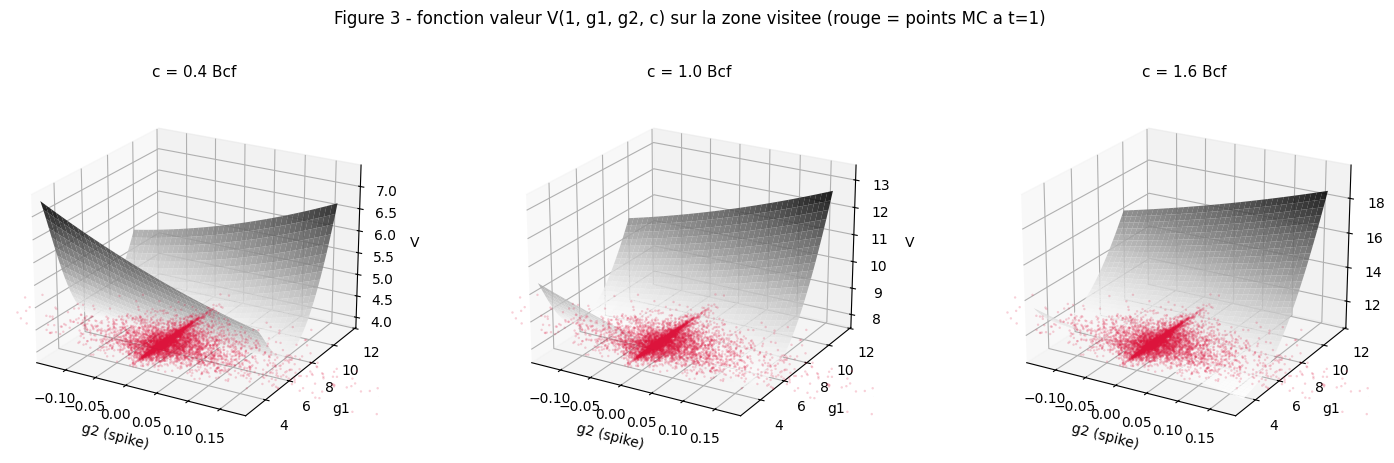

In [1]:
"""
BLSM — Exemple 3 : modèle de prix à deux facteurs avec sauts (Carmona-Ludkovski)
================================================================================
Reproduction de la FIGURE 3 : surface de la fonction valeur V(1, g1, g2, c).

VERSION CORRIGÉE (découplée, sans biais de clairvoyance) :
- backward régresse la continuation E[V_{m+1}|F_m] (actualisée) sur la base
  évaluée au prix PRÉSENT (G1[m], G2[m]) -> cont_coefs ;
- forward et surface lisent cont_coefs[j][m] en (G1[m], G2[m]), jamais m+1.
Convention identique au moteur principal (notebook gelé).
"""
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa

REGIMES = (-1, 0, 1)
PARAMS = {
    "a1": 4.0, "g1_mr_level_log": np.log(6.0), "sig1": 0.5, "G1_0": 6.0,
    "a2": 26.0, "lam": 12.0, "mu_J": 0.02, "sig_J": 0.1, "G2_0": 0.0,
    "C_max": 2.0, "C0": 1.0, "gas_loss": 0.0017 * 365.0, "r": 0.06, "T": 2.0,
}
CFG = {"M": 300, "N": 6000, "N_eval": 20000, "n_grid": 40, "degree": 3, "ridge": 1e-4}

def rate_in(c, p):
    return 0.0632*365.0*np.sqrt(np.maximum(1.0/(c+0.5)-1.0/2.5, 0.0))
def rate_out(c, p):
    return 0.177*365.0*np.sqrt(np.maximum(c, 0.0))

def make_basis(degree):
    def basis(g1, g2, c):
        x = np.log(np.maximum(np.asarray(g1, float), 1e-8))
        z = np.asarray(g2, float); y = np.asarray(c, float)
        cols = [np.ones_like(x)]
        for d in range(1, degree+1):
            for i in range(d+1):
                cols.append(x**(d-i)*y**i)
        cols += [z, z*z, z*x, z*y, z*x*y]
        return np.column_stack(cols)
    return basis

def total_price(g1, g2): return g1*np.exp(g2)
def terminal_value(g1, g2, c): return np.zeros_like(np.asarray(g1, float))

def step_dynamics(r, g1, g2, c, params, dt):
    g = total_price(g1, g2)
    if r == -1:
        rate = np.maximum(np.minimum(rate_in(c, params), (params["C_max"]-c)/dt), 0.0)
        cf = -rate*(g+params["gas_loss"])*dt; c_next = np.clip(c+rate*dt, 0.0, params["C_max"])
    elif r == 1:
        rate = np.maximum(np.minimum(rate_out(c, params), c/dt), 0.0)
        cf = rate*g*dt; c_next = np.clip(c-rate*dt, 0.0, params["C_max"])
    else:
        cf = np.zeros_like(np.asarray(g, float)); c_next = np.asarray(c, float).copy()
    return cf, c_next

def simulate_prices(M, N, params, rng):
    dt = params["T"]/M; sq = np.sqrt(dt)
    G1 = np.empty((M+1, N)); G2 = np.empty((M+1, N))
    G1[0] = params["G1_0"]; G2[0] = params["G2_0"]
    a1, sig1 = params["a1"], params["sig1"]; a2, lam = params["a2"], params["lam"]
    muJ, sigJ = params["mu_J"], params["sig_J"]; comp = lam*muJ*dt; decay2 = np.exp(-a2*dt)
    for m in range(M):
        g1 = G1[m]; dW = rng.standard_normal(N)*sq
        drift1 = a1*(params["g1_mr_level_log"]-np.log(np.maximum(g1, 1e-8)))*g1*dt
        milstein = 0.5*sig1*sig1*g1*(dW*dW-dt)
        G1[m+1] = np.maximum(g1+drift1+sig1*g1*dW+milstein, 1e-6)
        n_jumps = rng.poisson(lam*dt, N)
        jump_sum = np.where(n_jumps > 0, rng.normal(muJ, sigJ, N)*n_jumps, 0.0)
        G2[m+1] = G2[m]*decay2 + jump_sum - comp
    return G1, G2

# ---------------------------------------------------------------------------
# BACKWARD DÉCOUPLÉ : renvoie cont_coefs (continuation pure, sans look-ahead)
# ---------------------------------------------------------------------------
def train_backward(cfg, params, rng, G1=None, G2=None):
    M, N = cfg["M"], cfg["N"]; dt = params["T"]/M; disc = np.exp(-params["r"]*dt)
    basis = make_basis(cfg["degree"])
    if G1 is None: G1, G2 = simulate_prices(M, N, params, rng)
    c_grid = np.linspace(0.0, params["C_max"], cfg["n_grid"])
    coefs = {i: [None]*M for i in REGIMES}        # enveloppe de Snell (interne)
    cont_coefs = {i: [None]*M for i in REGIMES}   # continuation pure (sortie)
    for m in range(M-1, -1, -1):
        g1n = np.repeat(G1[m], cfg["n_grid"]); g1x = np.repeat(G1[m+1], cfg["n_grid"])
        g2n = np.repeat(G2[m], cfg["n_grid"]); g2x = np.repeat(G2[m+1], cfg["n_grid"])
        c_now = np.tile(c_grid, N)
        Phi = basis(g1n, g2n, c_now)
        A = Phi.T@Phi + cfg["ridge"]*np.eye(Phi.shape[1])
        # (1) continuation : régresse la valeur FUTURE sur la base PRÉSENTE (g1n,g2n)
        for j in REGIMES:
            if m == M-1:
                V_next = terminal_value(g1x, g2x, c_now)
            else:
                V_next = basis(g1x, g2x, c_now) @ coefs[j][m+1]
            cont_coefs[j][m] = np.linalg.solve(A, Phi.T @ (disc * V_next))
        # (2) enveloppe de Snell : propage la récurrence (lit cont_coefs en présent)
        for i in REGIMES:
            best = None
            for j in REGIMES:
                cf, c_next = step_dynamics(j, g1n, g2n, c_now, params, dt)
                cont = basis(g1n, g2n, c_next) @ cont_coefs[j][m]   # présent
                q = cf + cont
                best = q if best is None else np.maximum(best, q)
            coefs[i][m] = np.linalg.solve(A, Phi.T @ best)
    return cont_coefs, basis, (G1, G2)

# ---------------------------------------------------------------------------
# FORWARD PATHWISE : décision lit cont_coefs[j][m] en (G1[m],G2[m])
# ---------------------------------------------------------------------------
def value_forward(cont_coefs, basis, cfg, params, rng):
    M, N = cfg["M"], cfg["N_eval"]; dt = params["T"]/M; disc = np.exp(-params["r"]*dt)
    G1, G2 = simulate_prices(M, N, params, rng)
    c = np.full(N, params["C0"]); pv = np.zeros(N); df = 1.0
    for m in range(M):
        qs = np.empty((3, N)); cfs = np.empty((3, N)); cns = np.empty((3, N))
        for k, j in enumerate(REGIMES):
            cf, c_next = step_dynamics(j, G1[m], G2[m], c, params, dt)
            expected_cont = basis(G1[m], G2[m], c_next) @ cont_coefs[j][m]   # présent, sans look-ahead
            qs[k] = cf + expected_cont; cfs[k] = cf; cns[k] = c_next
        b = qs.argmax(axis=0); idx = np.arange(N)
        pv += df*cfs[b, idx]; c = cns[b, idx]; df *= disc
    return pv

# ---------------------------------------------------------------------------
# FIGURE 3 : surface de la continuation (régime store) à t=1
# ---------------------------------------------------------------------------
def plot_value_surfaces(cont_coefs, basis, cfg, params, c_levels=(0.4, 1.0, 1.6),
                        regime=0, n_pts=40, G1_sim=None, G2_sim=None, seed=11):
    """Surfaces de valeur sur la ZONE REELLEMENT VISITEE + nuage MC.
    Le facteur de spike g2 est tres concentre (reversion rapide a2=26) : on
    restreint la plage de g2 aux centiles 1-99 des trajectoires pour eviter
    l'extrapolation polynomiale hors du support. Le nuage rouge (points MC
    a t=1) montre que la surface n'extrapole pas dans le vide."""
    M = cfg["M"]; dt = params["T"] / M
    m_t1 = max(0, min(M - 1, int(round(1.0 / dt))))
    beta = cont_coefs[regime][m_t1]
    if G1_sim is None:
        G1_sim, G2_sim = simulate_prices(M, cfg["N"], params, np.random.default_rng(seed))
    g1_mc, g2_mc = G1_sim[m_t1], G2_sim[m_t1]
    g2_lo, g2_hi = np.percentile(g2_mc, 1), np.percentile(g2_mc, 99)
    g1_axis = np.linspace(3.0, 10.0, n_pts)
    g2_axis = np.linspace(g2_lo, g2_hi, n_pts)
    GG1, GG2 = np.meshgrid(g1_axis, g2_axis)
    fig = plt.figure(figsize=(15, 4.5))
    for idx, c_val in enumerate(c_levels):
        ax = fig.add_subplot(1, len(c_levels), idx + 1, projection="3d")
        cc = np.full(GG1.size, c_val)
        V = (basis(GG1.ravel(), GG2.ravel(), cc) @ beta).reshape(GG1.shape)
        ax.plot_surface(GG2, GG1, V, cmap="Greys", edgecolor="none", alpha=0.85)
        ax.scatter(g2_mc, g1_mc, np.full_like(g2_mc, V.min()),
                   s=3, c="crimson", alpha=0.20, edgecolors="none")
        ax.set_xlabel("g2 (spike)"); ax.set_ylabel("g1"); ax.set_zlabel("V")
        ax.set_xlim(g2_lo, g2_hi)
        ax.set_title(f"c = {c_val} Bcf", fontsize=11)
        ax.view_init(elev=22, azim=-60)
    fig.suptitle("Figure 3 - fonction valeur V(1, g1, g2, c) sur la zone visitee "
                 "(rouge = points MC a t=1)", y=1.02)
    plt.tight_layout()
    plt.show()
    return fig


def run_all(cfg=CFG, params=PARAMS, seed=11):
    rng = np.random.default_rng(seed)
    G1, G2 = simulate_prices(cfg["M"], cfg["N"], params, rng)
    print(f"G1 mean={G1.mean():.2f} | G2 mean={G2.mean():.3f} std={G2.std():.3f} | G total mean={total_price(G1,G2).mean():.2f}")
    cont_coefs, basis, _ = train_backward(cfg, params, rng, G1=G1, G2=G2)
    pv = value_forward(cont_coefs, basis, cfg, params, rng)
    print(f"V0 (forward Pathwise, c=C0={params['C0']}) = {pv.mean():.4f} (± {pv.std()/np.sqrt(len(pv)):.4f})")
    plot_value_surfaces(cont_coefs, basis, cfg, params, G1_sim=G1, G2_sim=G2)
    return cont_coefs, basis

# Exécution
run_all()


G1 mean=5.94 | G2 mean=0.000 std=0.055 | G total mean=5.95
V0 (forward Pathwise, c=C0=1.0) = 9.8853 (± 0.0182)


FileNotFoundError: [Errno 2] No such file or directory: '/mnt/user-data/outputs/example3_value_surfaces.png'

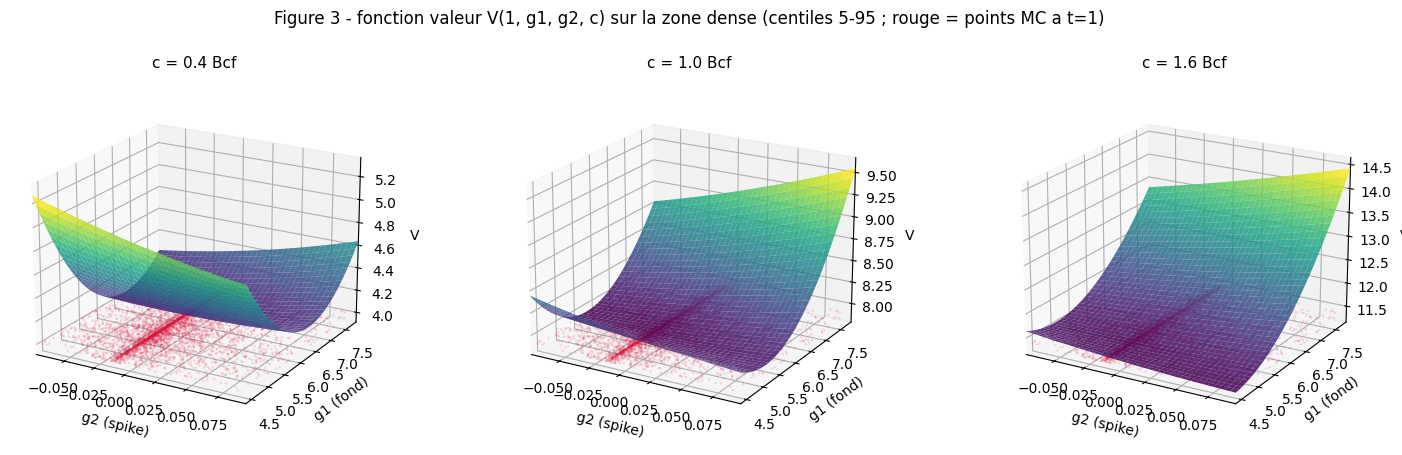

In [3]:
"""
BLSM — Exemple 3 : modèle de prix à deux facteurs avec sauts (Carmona-Ludkovski)
================================================================================
Reproduction de la FIGURE 3 : surface de la fonction valeur V(1, g1, g2, c).

VERSION CORRIGÉE (découplée, sans biais de clairvoyance) :
- backward régresse la continuation E[V_{m+1}|F_m] (actualisée) sur la base
  évaluée au prix PRÉSENT (G1[m], G2[m]) -> cont_coefs ;
- forward et surface lisent cont_coefs[j][m] en (G1[m], G2[m]), jamais m+1.
Convention identique au moteur principal (notebook gelé).
"""
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa

REGIMES = (-1, 0, 1)
PARAMS = {
    "a1": 4.0, "g1_mr_level_log": np.log(6.0), "sig1": 0.5, "G1_0": 6.0,
    "a2": 26.0, "lam": 12.0, "mu_J": 0.02, "sig_J": 0.1, "G2_0": 0.0,
    "C_max": 2.0, "C0": 1.0, "gas_loss": 0.0017 * 365.0, "r": 0.06, "T": 2.0,
}
CFG = {"M": 300, "N": 6000, "N_eval": 20000, "n_grid": 40, "degree": 3, "ridge": 1e-4}

def rate_in(c, p):
    return 0.0632*365.0*np.sqrt(np.maximum(1.0/(c+0.5)-1.0/2.5, 0.0))
def rate_out(c, p):
    return 0.177*365.0*np.sqrt(np.maximum(c, 0.0))

def make_basis(degree):
    def basis(g1, g2, c):
        x = np.log(np.maximum(np.asarray(g1, float), 1e-8))
        z = np.asarray(g2, float); y = np.asarray(c, float)
        cols = [np.ones_like(x)]
        for d in range(1, degree+1):
            for i in range(d+1):
                cols.append(x**(d-i)*y**i)
        cols += [z, z*z, z*x, z*y, z*x*y]
        return np.column_stack(cols)
    return basis

def total_price(g1, g2): return g1*np.exp(g2)
def terminal_value(g1, g2, c): return np.zeros_like(np.asarray(g1, float))

def step_dynamics(r, g1, g2, c, params, dt):
    g = total_price(g1, g2)
    if r == -1:
        rate = np.maximum(np.minimum(rate_in(c, params), (params["C_max"]-c)/dt), 0.0)
        cf = -rate*(g+params["gas_loss"])*dt; c_next = np.clip(c+rate*dt, 0.0, params["C_max"])
    elif r == 1:
        rate = np.maximum(np.minimum(rate_out(c, params), c/dt), 0.0)
        cf = rate*g*dt; c_next = np.clip(c-rate*dt, 0.0, params["C_max"])
    else:
        cf = np.zeros_like(np.asarray(g, float)); c_next = np.asarray(c, float).copy()
    return cf, c_next

def simulate_prices(M, N, params, rng):
    dt = params["T"]/M; sq = np.sqrt(dt)
    G1 = np.empty((M+1, N)); G2 = np.empty((M+1, N))
    G1[0] = params["G1_0"]; G2[0] = params["G2_0"]
    a1, sig1 = params["a1"], params["sig1"]; a2, lam = params["a2"], params["lam"]
    muJ, sigJ = params["mu_J"], params["sig_J"]; comp = lam*muJ*dt; decay2 = np.exp(-a2*dt)
    for m in range(M):
        g1 = G1[m]; dW = rng.standard_normal(N)*sq
        drift1 = a1*(params["g1_mr_level_log"]-np.log(np.maximum(g1, 1e-8)))*g1*dt
        milstein = 0.5*sig1*sig1*g1*(dW*dW-dt)
        G1[m+1] = np.maximum(g1+drift1+sig1*g1*dW+milstein, 1e-6)
        n_jumps = rng.poisson(lam*dt, N)
        jump_sum = np.where(n_jumps > 0, rng.normal(muJ, sigJ, N)*n_jumps, 0.0)
        G2[m+1] = G2[m]*decay2 + jump_sum - comp
    return G1, G2

# ---------------------------------------------------------------------------
# BACKWARD DÉCOUPLÉ : renvoie cont_coefs (continuation pure, sans look-ahead)
# ---------------------------------------------------------------------------
def train_backward(cfg, params, rng, G1=None, G2=None):
    M, N = cfg["M"], cfg["N"]; dt = params["T"]/M; disc = np.exp(-params["r"]*dt)
    basis = make_basis(cfg["degree"])
    if G1 is None: G1, G2 = simulate_prices(M, N, params, rng)
    c_grid = np.linspace(0.0, params["C_max"], cfg["n_grid"])
    coefs = {i: [None]*M for i in REGIMES}        # enveloppe de Snell (interne)
    cont_coefs = {i: [None]*M for i in REGIMES}   # continuation pure (sortie)
    for m in range(M-1, -1, -1):
        g1n = np.repeat(G1[m], cfg["n_grid"]); g1x = np.repeat(G1[m+1], cfg["n_grid"])
        g2n = np.repeat(G2[m], cfg["n_grid"]); g2x = np.repeat(G2[m+1], cfg["n_grid"])
        c_now = np.tile(c_grid, N)
        Phi = basis(g1n, g2n, c_now)
        A = Phi.T@Phi + cfg["ridge"]*np.eye(Phi.shape[1])
        # (1) continuation : régresse la valeur FUTURE sur la base PRÉSENTE (g1n,g2n)
        for j in REGIMES:
            if m == M-1:
                V_next = terminal_value(g1x, g2x, c_now)
            else:
                V_next = basis(g1x, g2x, c_now) @ coefs[j][m+1]
            cont_coefs[j][m] = np.linalg.solve(A, Phi.T @ (disc * V_next))
        # (2) enveloppe de Snell : propage la récurrence (lit cont_coefs en présent)
        for i in REGIMES:
            best = None
            for j in REGIMES:
                cf, c_next = step_dynamics(j, g1n, g2n, c_now, params, dt)
                cont = basis(g1n, g2n, c_next) @ cont_coefs[j][m]   # présent
                q = cf + cont
                best = q if best is None else np.maximum(best, q)
            coefs[i][m] = np.linalg.solve(A, Phi.T @ best)
    return cont_coefs, basis, (G1, G2)

# ---------------------------------------------------------------------------
# FORWARD PATHWISE : décision lit cont_coefs[j][m] en (G1[m],G2[m])
# ---------------------------------------------------------------------------
def value_forward(cont_coefs, basis, cfg, params, rng):
    M, N = cfg["M"], cfg["N_eval"]; dt = params["T"]/M; disc = np.exp(-params["r"]*dt)
    G1, G2 = simulate_prices(M, N, params, rng)
    c = np.full(N, params["C0"]); pv = np.zeros(N); df = 1.0
    for m in range(M):
        qs = np.empty((3, N)); cfs = np.empty((3, N)); cns = np.empty((3, N))
        for k, j in enumerate(REGIMES):
            cf, c_next = step_dynamics(j, G1[m], G2[m], c, params, dt)
            expected_cont = basis(G1[m], G2[m], c_next) @ cont_coefs[j][m]   # présent, sans look-ahead
            qs[k] = cf + expected_cont; cfs[k] = cf; cns[k] = c_next
        b = qs.argmax(axis=0); idx = np.arange(N)
        pv += df*cfs[b, idx]; c = cns[b, idx]; df *= disc
    return pv

# ---------------------------------------------------------------------------
# FIGURE 3 : surface de la continuation (régime store) à t=1
# ---------------------------------------------------------------------------
def plot_value_surfaces(cont_coefs, basis, cfg, params, c_levels=(0.4, 1.0, 1.6),
                        regime=0, n_pts=40, G1_sim=None, G2_sim=None, seed=11):
    """Surfaces de valeur sur la ZONE DENSE (centiles 5-95 de g1 ET g2) + nuage MC.
    Le facteur de spike g2 est tres concentre (reversion rapide a2=26) et g1,g2 ne
    sont pas visites a tous les coins du rectangle : on restreint aux centiles 5-95
    de chaque facteur pour eviter l'extrapolation polynomiale hors du support. Le
    nuage rouge (points MC a t=1) confirme que la surface couvre les etats reels."""
    M = cfg["M"]; dt = params["T"] / M
    m_t1 = max(0, min(M - 1, int(round(1.0 / dt))))
    beta = cont_coefs[regime][m_t1]
    if G1_sim is None:
        G1_sim, G2_sim = simulate_prices(M, cfg["N"], params, np.random.default_rng(seed))
    g1_mc, g2_mc = G1_sim[m_t1], G2_sim[m_t1]
    # zone dense : centiles 5-95 de chaque facteur
    g1_lo, g1_hi = np.percentile(g1_mc, 5), np.percentile(g1_mc, 95)
    g2_lo, g2_hi = np.percentile(g2_mc, 5), np.percentile(g2_mc, 95)
    mask = ((g1_mc >= g1_lo) & (g1_mc <= g1_hi) &
            (g2_mc >= g2_lo) & (g2_mc <= g2_hi))
    g1_axis = np.linspace(g1_lo, g1_hi, n_pts)
    g2_axis = np.linspace(g2_lo, g2_hi, n_pts)
    GG1, GG2 = np.meshgrid(g1_axis, g2_axis)
    fig = plt.figure(figsize=(15, 4.5))
    for idx, c_val in enumerate(c_levels):
        ax = fig.add_subplot(1, len(c_levels), idx + 1, projection="3d")
        cc = np.full(GG1.size, c_val)
        V = (basis(GG1.ravel(), GG2.ravel(), cc) @ beta).reshape(GG1.shape)
        ax.plot_surface(GG2, GG1, V, cmap="viridis", edgecolor="none", alpha=0.85)
        ax.scatter(g2_mc[mask], g1_mc[mask], np.full(mask.sum(), V.min()),
                   s=3, c="crimson", alpha=0.15, edgecolors="none")
        ax.set_xlabel("g2 (spike)"); ax.set_ylabel("g1 (fond)"); ax.set_zlabel("V")
        ax.set_xlim(g2_lo, g2_hi); ax.set_ylim(g1_lo, g1_hi)
        ax.set_title(f"c = {c_val} Bcf", fontsize=11)
        ax.view_init(elev=20, azim=-60)
    fig.suptitle("Figure 3 - fonction valeur V(1, g1, g2, c) sur la zone dense "
                 "(centiles 5-95 ; rouge = points MC a t=1)", y=1.0)
    plt.tight_layout()
    plt.show()
    return fig


def run_all(cfg=CFG, params=PARAMS, seed=11):
    rng = np.random.default_rng(seed)
    G1, G2 = simulate_prices(cfg["M"], cfg["N"], params, rng)
    print(f"G1 mean={G1.mean():.2f} | G2 mean={G2.mean():.3f} std={G2.std():.3f} | G total mean={total_price(G1,G2).mean():.2f}")
    cont_coefs, basis, _ = train_backward(cfg, params, rng, G1=G1, G2=G2)
    pv = value_forward(cont_coefs, basis, cfg, params, rng)
    print(f"V0 (forward Pathwise, c=C0={params['C0']}) = {pv.mean():.4f} (± {pv.std()/np.sqrt(len(pv)):.4f})")
    plot_value_surfaces(cont_coefs, basis, cfg, params, G1_sim=G1, G2_sim=G2)
    return cont_coefs, basis

# Exécution
run_all()


G1 mean=5.94 | G2 mean=0.000 std=0.055 | G total mean=5.95
V0 (forward Pathwise, c=C0=1.0) = 9.8853 (± 0.0182)


FileNotFoundError: [Errno 2] No such file or directory: '/mnt/user-data/outputs/example3_value_surfaces.png'

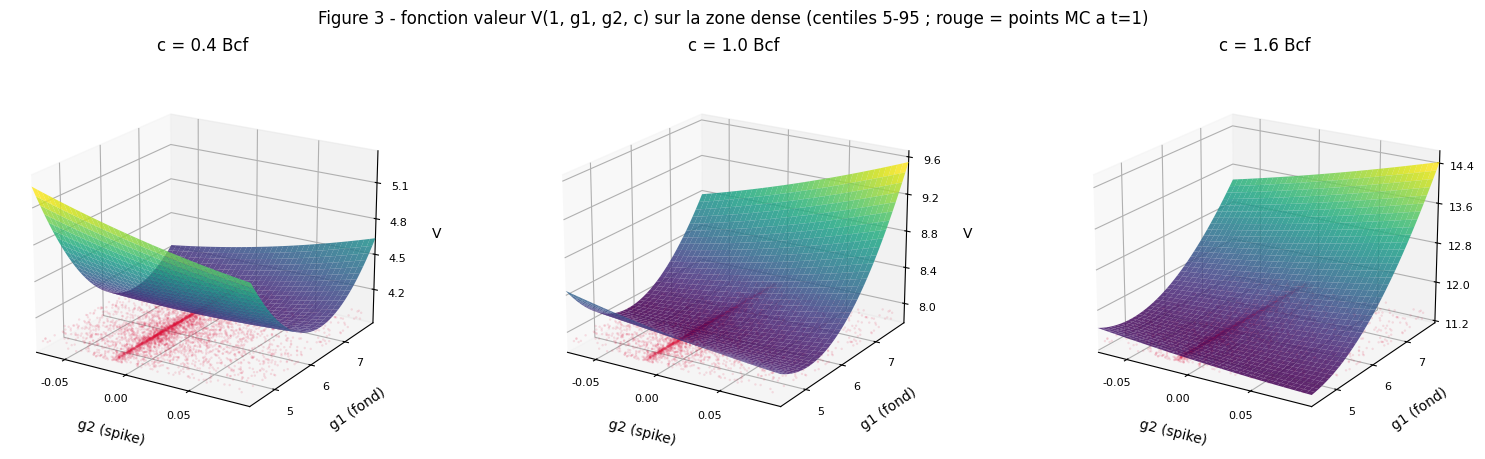

In [4]:
"""
BLSM — Exemple 3 : modèle de prix à deux facteurs avec sauts (Carmona-Ludkovski)
================================================================================
Reproduction de la FIGURE 3 : surface de la fonction valeur V(1, g1, g2, c).

VERSION CORRIGÉE (découplée, sans biais de clairvoyance) :
- backward régresse la continuation E[V_{m+1}|F_m] (actualisée) sur la base
  évaluée au prix PRÉSENT (G1[m], G2[m]) -> cont_coefs ;
- forward et surface lisent cont_coefs[j][m] en (G1[m], G2[m]), jamais m+1.
Convention identique au moteur principal (notebook gelé).
"""
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa

REGIMES = (-1, 0, 1)
PARAMS = {
    "a1": 4.0, "g1_mr_level_log": np.log(6.0), "sig1": 0.5, "G1_0": 6.0,
    "a2": 26.0, "lam": 12.0, "mu_J": 0.02, "sig_J": 0.1, "G2_0": 0.0,
    "C_max": 2.0, "C0": 1.0, "gas_loss": 0.0017 * 365.0, "r": 0.06, "T": 2.0,
}
CFG = {"M": 300, "N": 6000, "N_eval": 20000, "n_grid": 40, "degree": 3, "ridge": 1e-4}

def rate_in(c, p):
    return 0.0632*365.0*np.sqrt(np.maximum(1.0/(c+0.5)-1.0/2.5, 0.0))
def rate_out(c, p):
    return 0.177*365.0*np.sqrt(np.maximum(c, 0.0))

def make_basis(degree):
    def basis(g1, g2, c):
        x = np.log(np.maximum(np.asarray(g1, float), 1e-8))
        z = np.asarray(g2, float); y = np.asarray(c, float)
        cols = [np.ones_like(x)]
        for d in range(1, degree+1):
            for i in range(d+1):
                cols.append(x**(d-i)*y**i)
        cols += [z, z*z, z*x, z*y, z*x*y]
        return np.column_stack(cols)
    return basis

def total_price(g1, g2): return g1*np.exp(g2)
def terminal_value(g1, g2, c): return np.zeros_like(np.asarray(g1, float))

def step_dynamics(r, g1, g2, c, params, dt):
    g = total_price(g1, g2)
    if r == -1:
        rate = np.maximum(np.minimum(rate_in(c, params), (params["C_max"]-c)/dt), 0.0)
        cf = -rate*(g+params["gas_loss"])*dt; c_next = np.clip(c+rate*dt, 0.0, params["C_max"])
    elif r == 1:
        rate = np.maximum(np.minimum(rate_out(c, params), c/dt), 0.0)
        cf = rate*g*dt; c_next = np.clip(c-rate*dt, 0.0, params["C_max"])
    else:
        cf = np.zeros_like(np.asarray(g, float)); c_next = np.asarray(c, float).copy()
    return cf, c_next

def simulate_prices(M, N, params, rng):
    dt = params["T"]/M; sq = np.sqrt(dt)
    G1 = np.empty((M+1, N)); G2 = np.empty((M+1, N))
    G1[0] = params["G1_0"]; G2[0] = params["G2_0"]
    a1, sig1 = params["a1"], params["sig1"]; a2, lam = params["a2"], params["lam"]
    muJ, sigJ = params["mu_J"], params["sig_J"]; comp = lam*muJ*dt; decay2 = np.exp(-a2*dt)
    for m in range(M):
        g1 = G1[m]; dW = rng.standard_normal(N)*sq
        drift1 = a1*(params["g1_mr_level_log"]-np.log(np.maximum(g1, 1e-8)))*g1*dt
        milstein = 0.5*sig1*sig1*g1*(dW*dW-dt)
        G1[m+1] = np.maximum(g1+drift1+sig1*g1*dW+milstein, 1e-6)
        n_jumps = rng.poisson(lam*dt, N)
        jump_sum = np.where(n_jumps > 0, rng.normal(muJ, sigJ, N)*n_jumps, 0.0)
        G2[m+1] = G2[m]*decay2 + jump_sum - comp
    return G1, G2

# ---------------------------------------------------------------------------
# BACKWARD DÉCOUPLÉ : renvoie cont_coefs (continuation pure, sans look-ahead)
# ---------------------------------------------------------------------------
def train_backward(cfg, params, rng, G1=None, G2=None):
    M, N = cfg["M"], cfg["N"]; dt = params["T"]/M; disc = np.exp(-params["r"]*dt)
    basis = make_basis(cfg["degree"])
    if G1 is None: G1, G2 = simulate_prices(M, N, params, rng)
    c_grid = np.linspace(0.0, params["C_max"], cfg["n_grid"])
    coefs = {i: [None]*M for i in REGIMES}        # enveloppe de Snell (interne)
    cont_coefs = {i: [None]*M for i in REGIMES}   # continuation pure (sortie)
    for m in range(M-1, -1, -1):
        g1n = np.repeat(G1[m], cfg["n_grid"]); g1x = np.repeat(G1[m+1], cfg["n_grid"])
        g2n = np.repeat(G2[m], cfg["n_grid"]); g2x = np.repeat(G2[m+1], cfg["n_grid"])
        c_now = np.tile(c_grid, N)
        Phi = basis(g1n, g2n, c_now)
        A = Phi.T@Phi + cfg["ridge"]*np.eye(Phi.shape[1])
        # (1) continuation : régresse la valeur FUTURE sur la base PRÉSENTE (g1n,g2n)
        for j in REGIMES:
            if m == M-1:
                V_next = terminal_value(g1x, g2x, c_now)
            else:
                V_next = basis(g1x, g2x, c_now) @ coefs[j][m+1]
            cont_coefs[j][m] = np.linalg.solve(A, Phi.T @ (disc * V_next))
        # (2) enveloppe de Snell : propage la récurrence (lit cont_coefs en présent)
        for i in REGIMES:
            best = None
            for j in REGIMES:
                cf, c_next = step_dynamics(j, g1n, g2n, c_now, params, dt)
                cont = basis(g1n, g2n, c_next) @ cont_coefs[j][m]   # présent
                q = cf + cont
                best = q if best is None else np.maximum(best, q)
            coefs[i][m] = np.linalg.solve(A, Phi.T @ best)
    return cont_coefs, basis, (G1, G2)

# ---------------------------------------------------------------------------
# FORWARD PATHWISE : décision lit cont_coefs[j][m] en (G1[m],G2[m])
# ---------------------------------------------------------------------------
def value_forward(cont_coefs, basis, cfg, params, rng):
    M, N = cfg["M"], cfg["N_eval"]; dt = params["T"]/M; disc = np.exp(-params["r"]*dt)
    G1, G2 = simulate_prices(M, N, params, rng)
    c = np.full(N, params["C0"]); pv = np.zeros(N); df = 1.0
    for m in range(M):
        qs = np.empty((3, N)); cfs = np.empty((3, N)); cns = np.empty((3, N))
        for k, j in enumerate(REGIMES):
            cf, c_next = step_dynamics(j, G1[m], G2[m], c, params, dt)
            expected_cont = basis(G1[m], G2[m], c_next) @ cont_coefs[j][m]   # présent, sans look-ahead
            qs[k] = cf + expected_cont; cfs[k] = cf; cns[k] = c_next
        b = qs.argmax(axis=0); idx = np.arange(N)
        pv += df*cfs[b, idx]; c = cns[b, idx]; df *= disc
    return pv

# ---------------------------------------------------------------------------
# FIGURE 3 : surface de la continuation (régime store) à t=1
# ---------------------------------------------------------------------------
def plot_value_surfaces(cont_coefs, basis, cfg, params, c_levels=(0.4, 1.0, 1.6),
                        regime=0, n_pts=40, G1_sim=None, G2_sim=None, seed=11):
    """Surfaces de valeur sur la ZONE DENSE (centiles 5-95 de g1 ET g2) + nuage MC.
    Axes formates pour la lisibilite (peu de graduations, format court)."""
    from matplotlib.ticker import FormatStrFormatter, MaxNLocator
    M = cfg["M"]; dt = params["T"] / M
    m_t1 = max(0, min(M - 1, int(round(1.0 / dt))))
    beta = cont_coefs[regime][m_t1]
    if G1_sim is None:
        G1_sim, G2_sim = simulate_prices(M, cfg["N"], params, np.random.default_rng(seed))
    g1_mc, g2_mc = G1_sim[m_t1], G2_sim[m_t1]
    g1_lo, g1_hi = np.percentile(g1_mc, 5), np.percentile(g1_mc, 95)
    g2_lo, g2_hi = np.percentile(g2_mc, 5), np.percentile(g2_mc, 95)
    mask = ((g1_mc >= g1_lo) & (g1_mc <= g1_hi) &
            (g2_mc >= g2_lo) & (g2_mc <= g2_hi))
    g1_axis = np.linspace(g1_lo, g1_hi, n_pts)
    g2_axis = np.linspace(g2_lo, g2_hi, n_pts)
    GG1, GG2 = np.meshgrid(g1_axis, g2_axis)
    fig = plt.figure(figsize=(16, 5))
    for idx, c_val in enumerate(c_levels):
        ax = fig.add_subplot(1, len(c_levels), idx + 1, projection="3d")
        cc = np.full(GG1.size, c_val)
        V = (basis(GG1.ravel(), GG2.ravel(), cc) @ beta).reshape(GG1.shape)
        ax.plot_surface(GG2, GG1, V, cmap="viridis", edgecolor="none", alpha=0.85)
        ax.scatter(g2_mc[mask], g1_mc[mask], np.full(mask.sum(), V.min()),
                   s=3, c="crimson", alpha=0.12, edgecolors="none")
        ax.set_xlabel("g2 (spike)", labelpad=8, fontsize=10)
        ax.set_ylabel("g1 (fond)", labelpad=8, fontsize=10)
        ax.set_zlabel("V", labelpad=6, fontsize=10)
        ax.xaxis.set_major_locator(MaxNLocator(4)); ax.xaxis.set_major_formatter(FormatStrFormatter("%.2f"))
        ax.yaxis.set_major_locator(MaxNLocator(4)); ax.yaxis.set_major_formatter(FormatStrFormatter("%.0f"))
        ax.zaxis.set_major_locator(MaxNLocator(5)); ax.zaxis.set_major_formatter(FormatStrFormatter("%.1f"))
        ax.tick_params(axis="x", labelsize=8, pad=2)
        ax.tick_params(axis="y", labelsize=8, pad=2)
        ax.tick_params(axis="z", labelsize=8, pad=2)
        ax.set_xlim(g2_lo, g2_hi); ax.set_ylim(g1_lo, g1_hi)
        ax.set_title(f"c = {c_val} Bcf", fontsize=12, pad=10)
        ax.view_init(elev=20, azim=-58)
    fig.suptitle("Figure 3 - fonction valeur V(1, g1, g2, c) sur la zone dense "
                 "(centiles 5-95 ; rouge = points MC a t=1)", y=0.99, fontsize=12)
    plt.subplots_adjust(left=0.02, right=0.98, wspace=0.12, top=0.88)
    plt.show()
    return fig


def run_all(cfg=CFG, params=PARAMS, seed=11):
    rng = np.random.default_rng(seed)
    G1, G2 = simulate_prices(cfg["M"], cfg["N"], params, rng)
    print(f"G1 mean={G1.mean():.2f} | G2 mean={G2.mean():.3f} std={G2.std():.3f} | G total mean={total_price(G1,G2).mean():.2f}")
    cont_coefs, basis, _ = train_backward(cfg, params, rng, G1=G1, G2=G2)
    pv = value_forward(cont_coefs, basis, cfg, params, rng)
    print(f"V0 (forward Pathwise, c=C0={params['C0']}) = {pv.mean():.4f} (± {pv.std()/np.sqrt(len(pv)):.4f})")
    plot_value_surfaces(cont_coefs, basis, cfg, params, G1_sim=G1, G2_sim=G2)
    return cont_coefs, basis

# Exécution
run_all()


## Validation économique — sensibilité à l'intensité de saut

Au-delà de la forme de la surface, on vérifie que le modèle capture la **valeur des spikes** : la valeur du stockage doit croître avec l'intensité de saut $\lambda$, chaque pic de prix offrant une opportunité de soutirage à prix élevé. C'est la valeur d'option sur les sauts, qu'un modèle à un seul facteur ne peut représenter.

In [2]:
# ============================================================
#  Validation économique — sensibilité à l'intensité de saut lambda
#  La valeur du stockage doit CROÎTRE avec lambda : plus de spikes
#  de prix = plus d'opportunités de soutirage à prix élevé.
#  C'est la valeur d'option sur les sauts, qu'un modèle mono-facteur
#  ne peut capturer.
# ============================================================
print("Sensibilité de V0 à l'intensité de saut (lambda)")
print(f"{'lambda':>8}{'V0':>10}{'± IC95':>9}")
print("-" * 27)
for lam in (6.0, 12.0, 24.0):
    p = dict(PARAMS, lam=lam)
    rng = np.random.default_rng(11)
    cc, basis, _ = train_backward(CFG, p, rng)
    pv = value_forward(cc, basis, CFG, p, np.random.default_rng(200))
    ic = 1.96 * pv.std() / np.sqrt(len(pv))
    print(f"{lam:>8.1f}{pv.mean():>10.3f}{ic:>9.3f}")
print("\nV0 croît avec lambda : la flexibilité du stockage tire sa valeur")
print("des pics de prix (chaque spike = opportunité de vente).")


Sensibilité de V0 à l'intensité de saut (lambda)
  lambda        V0   ± IC95
---------------------------
     6.0     9.059    0.031
    12.0     9.933    0.036
    24.0    11.679    0.043

V0 croît avec lambda : la flexibilité du stockage tire sa valeur
des pics de prix (chaque spike = opportunité de vente).


## Synthèse — Exemple 3

La surface présente une forme de **bol asymétrique** : la valeur croît avec le facteur de fond $g_1$, avec le facteur de spike $g_2$, et avec l'inventaire — conforme à Carmona \& Ludkovski. Cette extension **multi-facteurs** (deux facteurs $G=G_1 e^{G_2}$ avec sauts de Poisson) ne modifie que la *physique du prix* : le moteur de switching découplé reste identique. L'architecture s'étend naturellement à un vecteur de facteurs corrélés (spreads inter-commodités).